# Ejemplo práctico de un modelo supervisado de regresión
---

Autor: Manuel Díaz Bendito

---

# 0 - Instalaciones necesarias e importación de librerías utilizadas

## Instalación de librerías

In [1]:
!pip install ucimlrepo

In [2]:
!pip install xgboost

In [3]:
!pip install scikit-plot

## Importación de librerías

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

import xgboost as xgb
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import random
import warnings
warnings.filterwarnings('ignore')

In [5]:
pd.options.display.max_columns = 100

# Semilla para reproducibilidad
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

# 1 - Carga, preparación y EDA de los datos

El objetivo de este notebook, dado el dataset [Auto MPG](https://archive.ics.uci.edu/dataset/9/auto+mpg), es desarrollar un modelo de **regresión supervisada** que prediga el **consumo de combustible (millas por galón, MPG)** de un coche a partir de sus características técnicas (cilindros, potencia, peso, etc.).

Es el problema dual al de los notebooks anteriores: en lugar de predecir una **categoría** (clasificación), aquí predecimos un **valor numérico continuo**.

## 1.1 - Carga del dataset

In [6]:
# Descargamos el dataset Auto MPG del repositorio UCI
auto_mpg = fetch_ucirepo(id=9)

df_train_raw = auto_mpg.data.features
df_target_raw = auto_mpg.data.targets

# Información del dataset
print(auto_mpg.metadata.name)
print(f"Nº de muestras: {df_train_raw.shape[0]}")
print(f"Nº de variables: {df_train_raw.shape[1]}")

Auto MPG
Nº de muestras: 398
Nº de variables: 7


In [7]:
df_train_raw.head()

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin
0,307.0,8,130.0,3504,12.0,70,1
1,350.0,8,165.0,3693,11.5,70,1
2,318.0,8,150.0,3436,11.0,70,1
3,304.0,8,150.0,3433,12.0,70,1
4,302.0,8,140.0,3449,10.5,70,1


In [8]:
df_train_raw.shape

(398, 7)

In [9]:
df_target_raw.head()

,mpg
0,18.0
1,15.0
2,18.0
3,16.0
4,17.0


## 1.2 - Preparación del dataset

In [10]:
# Vemos cómo es la variable objetivo (target) inicialmente.
print('Variable objetivo: mpg (millas por galón)')
print(df_target_raw.describe())

Variable objetivo: mpg (millas por galón)
              mpg
count  398.000000
mean    23.514573
std      7.815984
min      9.000000
25%     17.500000
50%     23.000000
75%     29.000000
max     46.600000


In [11]:
# Unimos datos y target en el mismo dataframe para el análisis exploratorio.
df_train_raw = df_train_raw.copy()
df_train_raw['mpg'] = df_target_raw['mpg']
df_train_raw.head()

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
0,307.0,8,130.0,3504,12.0,70,1,18.0
1,350.0,8,165.0,3693,11.5,70,1,15.0
2,318.0,8,150.0,3436,11.0,70,1,18.0
3,304.0,8,150.0,3433,12.0,70,1,16.0
4,302.0,8,140.0,3449,10.5,70,1,17.0


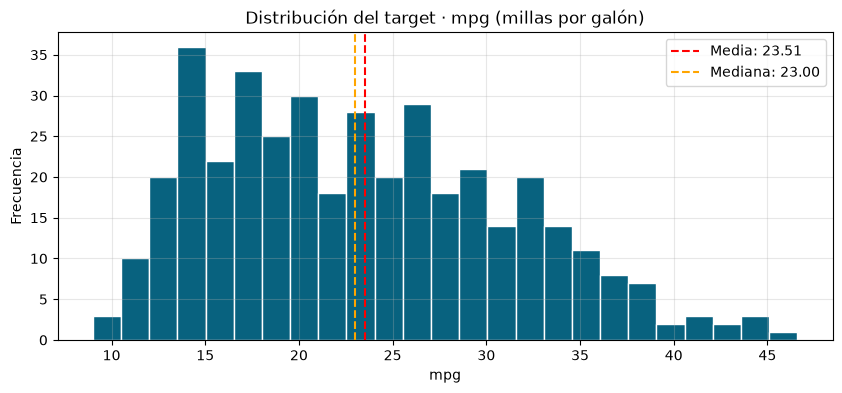

In [12]:
# Distribución de la variable objetivo: ¿es simétrica? ¿hay outliers?
plt.figure(figsize=(10, 4))
plt.hist(df_train_raw['mpg'], bins=25, color='#08627F', edgecolor='white')
plt.axvline(df_train_raw['mpg'].mean(), color='red', linestyle='--', label=f"Media: {df_train_raw['mpg'].mean():.2f}")
plt.axvline(df_train_raw['mpg'].median(), color='orange', linestyle='--', label=f"Mediana: {df_train_raw['mpg'].median():.2f}")
plt.title('Distribución del target · mpg (millas por galón)')
plt.xlabel('mpg'); plt.ylabel('Frecuencia'); plt.legend()
plt.grid(alpha=0.3); plt.show()

---

## 1.3 - EDA

### 1.3.1 - Exploración preliminar de las variables numéricas

In [13]:
df_train_raw.describe()

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
count,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,193.425879,5.454774,104.469388,2970.424623,15.568090,76.010050,1.572864,23.514573
std,104.269838,1.701004,38.491160,846.841774,2.757689,3.697627,0.802055,7.815984
min,68.000000,3.000000,46.000000,1613.000000,8.000000,70.000000,1.000000,9.000000
25%,104.250000,4.000000,75.000000,2223.750000,13.825000,73.000000,1.000000,17.500000
50%,148.500000,4.000000,93.500000,2803.500000,15.500000,76.000000,1.000000,23.000000
75%,262.000000,8.000000,126.000000,3608.000000,17.175000,79.000000,2.000000,29.000000
max,455.000000,8.000000,230.000000,5140.000000,24.800000,82.000000,3.000000,46.600000


In [14]:
# Correlaciones con el target: variables más informativas para el modelo
corr = df_train_raw.corr(numeric_only=True)
corr

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
displacement,1.000000,0.950721,0.897257,0.932824,-0.543684,-0.370164,-0.609409,-0.804203
cylinders,0.950721,1.000000,0.842983,0.896017,-0.505419,-0.348746,-0.562543,-0.775396
horsepower,0.897257,0.842983,1.000000,0.864538,-0.689196,-0.416361,-0.455171,-0.778427
weight,0.932824,0.896017,0.864538,1.000000,-0.417457,-0.306564,-0.581024,-0.831741
acceleration,-0.543684,-0.505419,-0.689196,-0.417457,1.000000,0.288137,0.205873,0.420289
model_year,-0.370164,-0.348746,-0.416361,-0.306564,0.288137,1.000000,0.180662,0.579267
origin,-0.609409,-0.562543,-0.455171,-0.581024,0.205873,0.180662,1.000000,0.563450
mpg,-0.804203,-0.775396,-0.778427,-0.831741,0.420289,0.579267,0.563450,1.000000


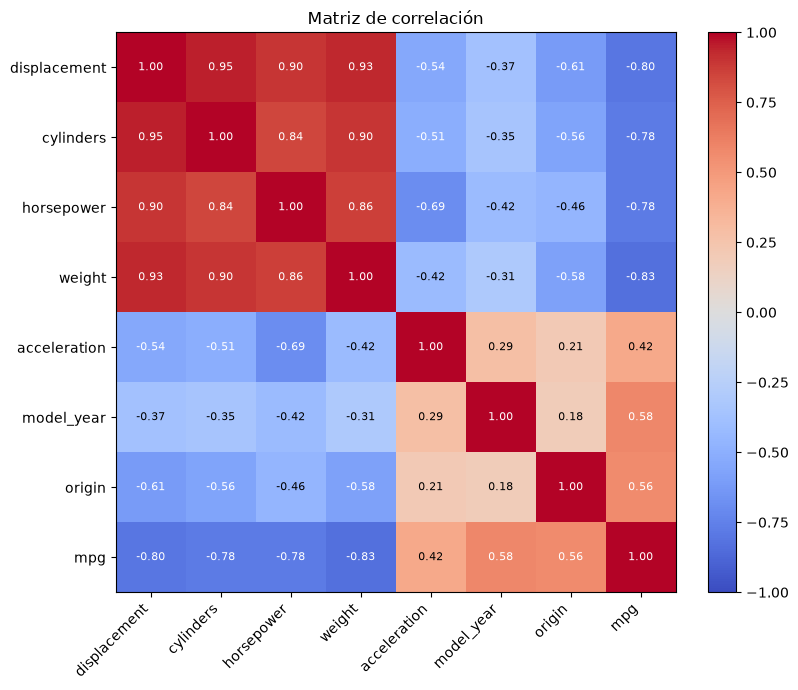

In [15]:
# Visualización de la matriz de correlación
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i,j]:.2f}', ha='center', va='center',
                color='white' if abs(corr.iloc[i,j])>0.5 else 'black', fontsize=8)
fig.colorbar(im, fraction=0.046, pad=0.04)
plt.title('Matriz de correlación')
plt.tight_layout(); plt.show()

---

Observación: variables como `weight`, `displacement`, `horsepower` y `cylinders` presentan correlación **negativa fuerte** con `mpg`: coches más pesados y potentes consumen más. Estas serán nuestras variables explicativas principales.

### 1.3.2 - Exploración gráfica y tabulada de las variables categóricas

In [19]:
def plot_cat_feat(df, feature, target='mpg', print_detail=False):
    """
    Para una variable categórica, muestra el conteo por categoría y el
    boxplot del target en cada una. Útil para ver si distintas categorías
    se asocian a distintos rangos del target.
    """
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    # Conteo por categoría
    conteos = df[feature].value_counts().sort_index()
    axes[0].bar(conteos.index.astype(str), conteos.values, color='#08627F')
    axes[0].set_title(f'Conteo por {feature}')
    axes[0].set_xlabel(feature); axes[0].set_ylabel('Nº muestras')
    for i, v in enumerate(conteos.values):
        axes[0].text(i, v+1, str(v), ha='center')

    # Boxplot del target por categoría
    cats = sorted(df[feature].dropna().unique())
    datos = [df[df[feature]==c][target].dropna().values for c in cats]
    axes[1].boxplot(datos, label=[str(c) for c in cats], patch_artist=True,
                    boxprops=dict(facecolor='#6ACBB8', color='#002D41'))
    axes[1].set_title(f'{target} por {feature}')
    axes[1].set_xlabel(feature); axes[1].set_ylabel(target)
    axes[1].grid(alpha=0.3)

    plt.tight_layout(); plt.show()

    if print_detail:
        print(df.groupby(feature)[target].agg(['mean','std','count']))

#### cylinders

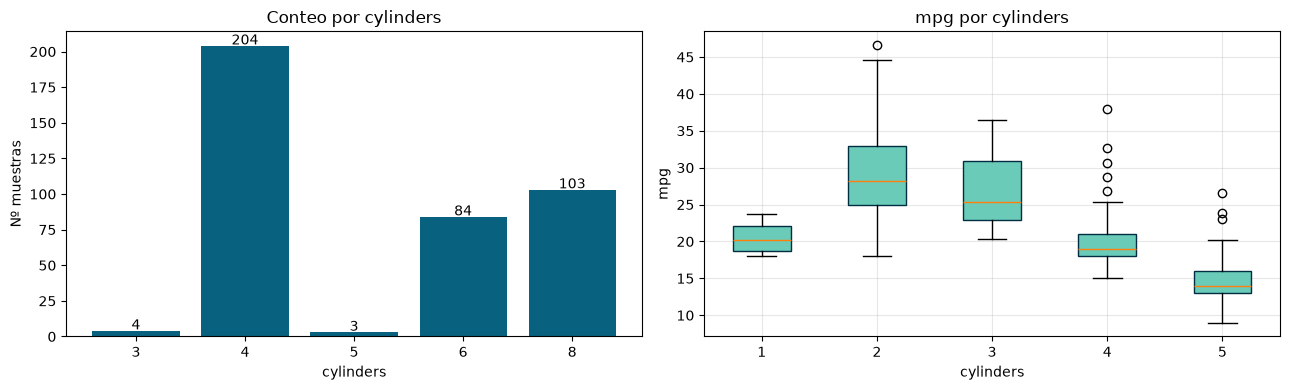

                mean       std  count
cylinders                            
3          20.550000  2.564501      4
4          29.286765  5.710156    204
5          27.366667  8.228204      3
6          19.985714  3.807322     84
8          14.963107  2.836284    103


In [20]:
plot_cat_feat(df_train_raw, 'cylinders', print_detail=True)

#### origin

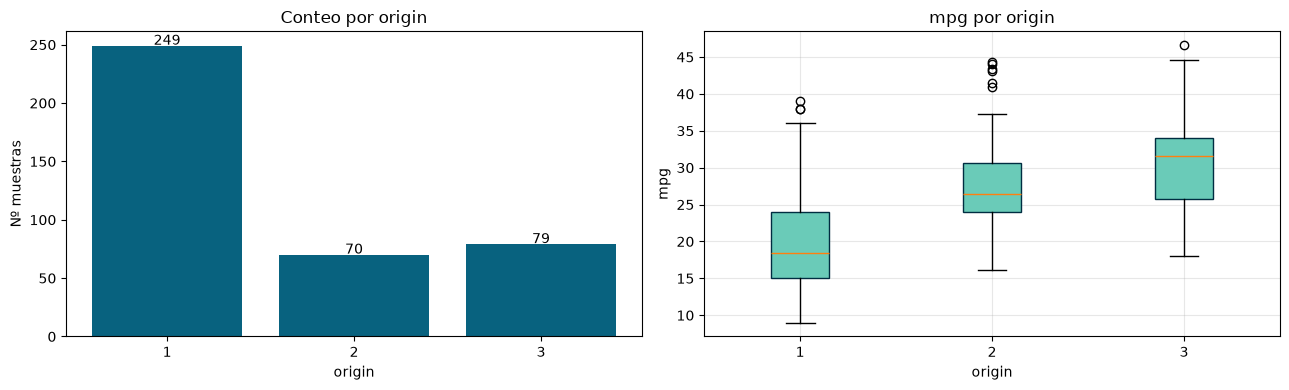

             mean       std  count
origin                            
1       20.083534  6.402892    249
2       27.891429  6.723930     70
3       30.450633  6.090048     79


In [21]:
# 1 = USA, 2 = Europa, 3 = Japón
plot_cat_feat(df_train_raw, 'origin', print_detail=True)

#### model_year

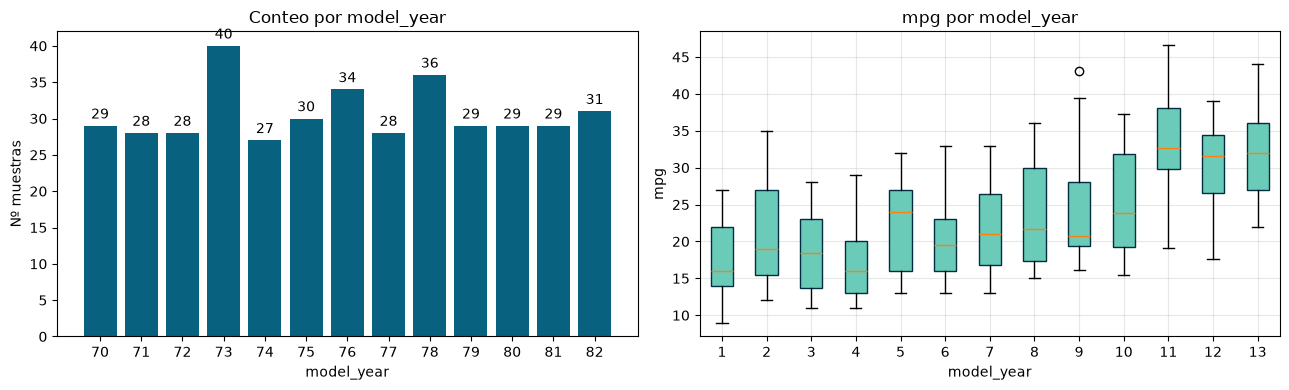

In [22]:
plot_cat_feat(df_train_raw, 'model_year')

### 1.3.3 - Exploración gráfica de las variables numéricas

In [23]:
def plot_num_feat(df, feat, bins, target='mpg', print_box=False):
    """
    Para una variable numérica, muestra histograma + scatter contra el target.
    El scatter permite ver visualmente si la relación con el target es lineal,
    monótona o no lineal.
    """
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    # Histograma
    axes[0].hist(df[feat].dropna(), bins=bins, color='#08627F', edgecolor='white')
    axes[0].set_title(f'Distribución de {feat}')
    axes[0].set_xlabel(feat); axes[0].set_ylabel('Frecuencia')
    axes[0].grid(alpha=0.3)

    # Scatter vs target
    axes[1].scatter(df[feat], df[target], alpha=0.5, color='#08627F')
    axes[1].set_title(f'{feat} vs {target}')
    axes[1].set_xlabel(feat); axes[1].set_ylabel(target)
    axes[1].grid(alpha=0.3)

    plt.tight_layout(); plt.show()

    if print_box:
        print(df[feat].describe())

#### displacement

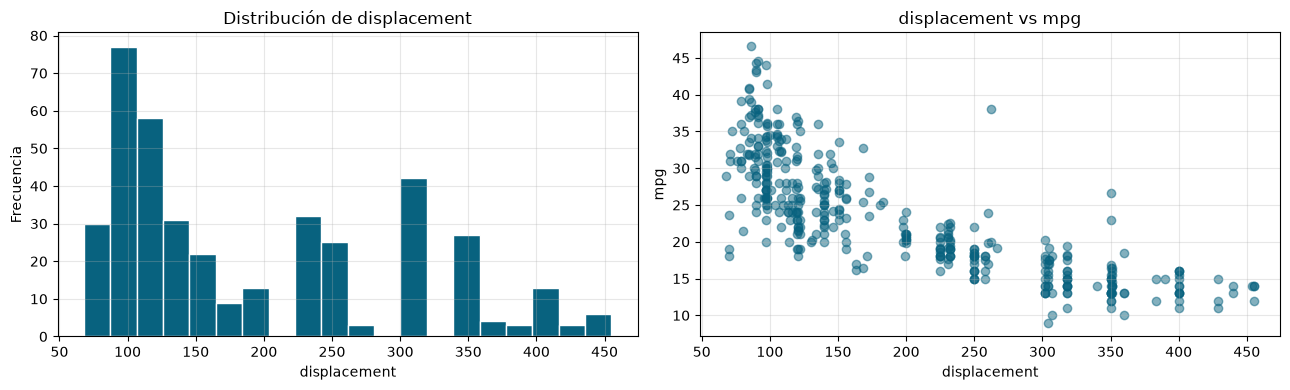

In [24]:
plot_num_feat(df_train_raw, 'displacement', bins=20)

#### horsepower

Nº de NaN en horsepower: 6


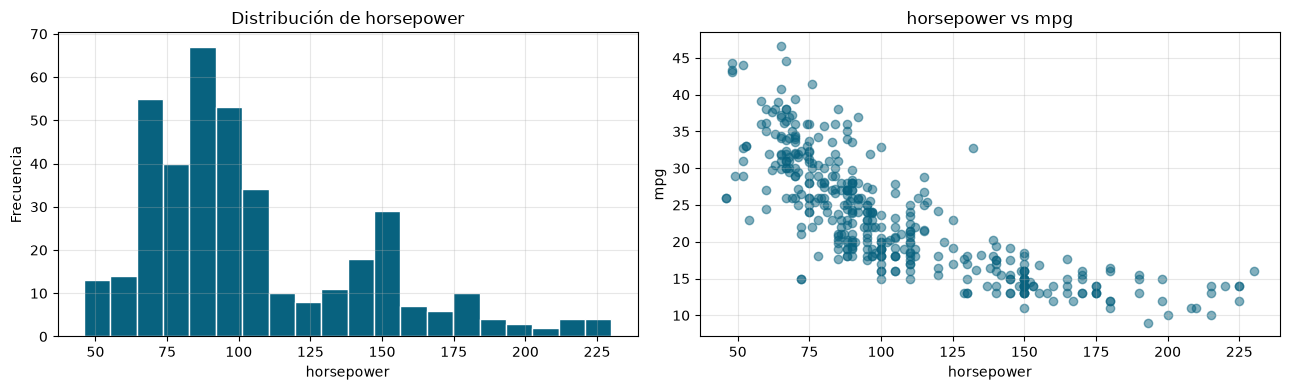

In [25]:
# Atención: horsepower tiene algunos valores faltantes
print(f"Nº de NaN en horsepower: {df_train_raw['horsepower'].isna().sum()}")
plot_num_feat(df_train_raw, 'horsepower', bins=20)

#### weight

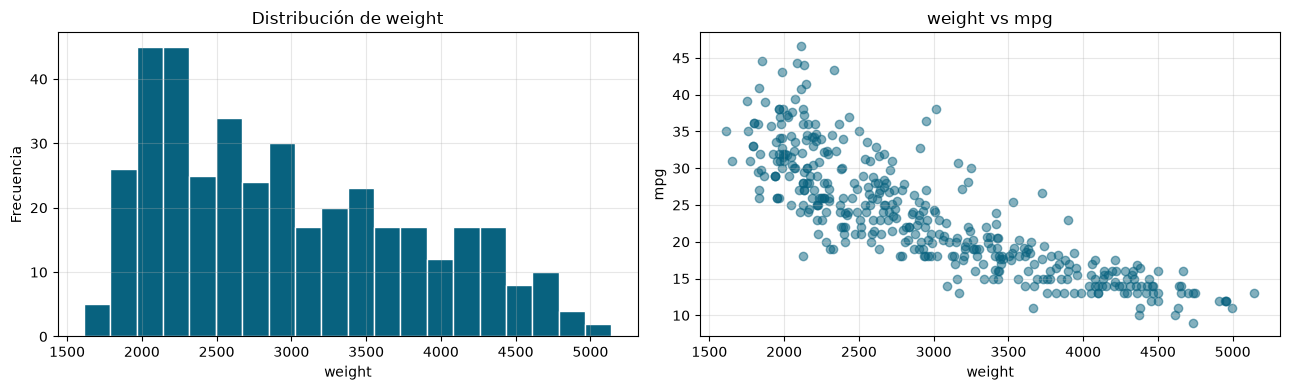

In [26]:
plot_num_feat(df_train_raw, 'weight', bins=20)

#### acceleration

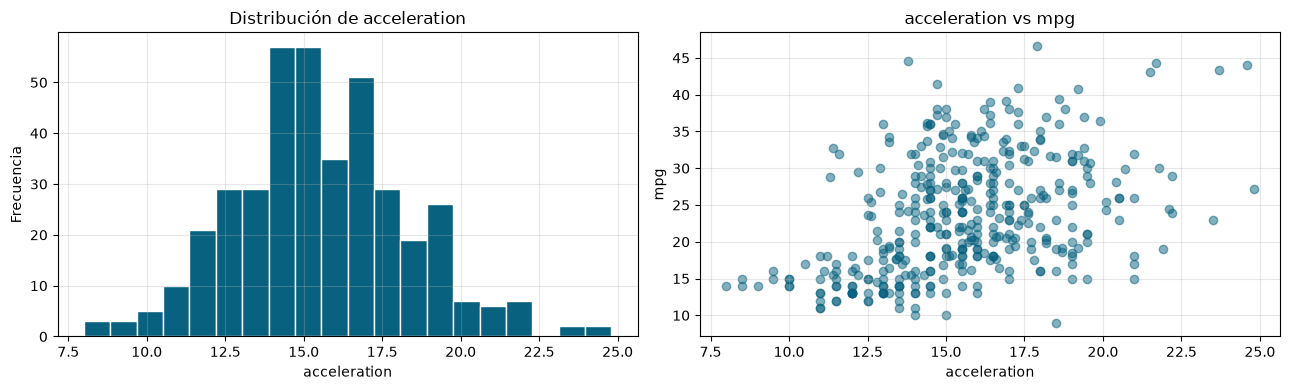

In [27]:
plot_num_feat(df_train_raw, 'acceleration', bins=20)

# 2 - Procesado e ingeniería de características

In [28]:
# Copiamos el dataset original para no realizar transformaciones sobre este.
df_train = df_train_raw.copy()
df_train.head()

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
0,307.0,8,130.0,3504,12.0,70,1,18.0
1,350.0,8,165.0,3693,11.5,70,1,15.0
2,318.0,8,150.0,3436,11.0,70,1,18.0
3,304.0,8,150.0,3433,12.0,70,1,16.0
4,302.0,8,140.0,3449,10.5,70,1,17.0


## 2.1 - Procesado de los datos

In [29]:
# Tratamiento de valores faltantes: horsepower tiene unos pocos NaNs.
# Estrategia: imputar con la mediana de la variable (más robusta a outliers que la media).
miss_val_feats = ['horsepower']
for feat in miss_val_feats:
    n_missing = df_train[feat].isna().sum()
    if n_missing > 0:
        mediana = df_train[feat].median()
        df_train[feat] = df_train[feat].fillna(mediana)
        print(f'{feat}: {n_missing} NaN imputados con la mediana ({mediana})')

horsepower: 6 NaN imputados con la mediana (93.5)


## 2.2 - Ingeniería de características

In [30]:
# Diccionario con información de las transformaciones a realizar para las
# diferentes características.
# - origin: variable categórica con 3 categorías -> one-hot encoding
# - cylinders: variable discreta con pocos valores -> la dejamos como numérica (mantiene orden)
# - model_year: variable discreta -> creamos una variable derivada que indica la "antigüedad" relativa
cat_feats2OH = ['origin']
mapeo_origen = {1: 'USA', 2: 'Europa', 3: 'Japon'}

### 2.2.1 - Ingeniería de características categóricas

In [31]:
# One-hot encoding de la variable origin
df_train['origin_label'] = df_train['origin'].map(mapeo_origen)
df_train = pd.get_dummies(df_train, columns=['origin_label'], prefix='origin', drop_first=False)

# Convertimos a int (algunas versiones de pandas crean booleanos)
for col in [c for c in df_train.columns if c.startswith('origin_')]:
    df_train[col] = df_train[col].astype(int)

print('Columnas one-hot creadas:', [c for c in df_train.columns if c.startswith('origin_')])
df_train.head()

Columnas one-hot creadas: ['origin_Europa', 'origin_Japon', 'origin_USA']


,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg,origin_Europa,origin_Japon,origin_USA
0,307.0,8,130.0,3504,12.0,70,1,18.0,0,0,1
1,350.0,8,165.0,3693,11.5,70,1,15.0,0,0,1
2,318.0,8,150.0,3436,11.0,70,1,18.0,0,0,1
3,304.0,8,150.0,3433,12.0,70,1,16.0,0,0,1
4,302.0,8,140.0,3449,10.5,70,1,17.0,0,0,1


### 2.2.2 - Ingeniería de características numéricas

In [32]:
# Creamos una variable derivada potencialmente útil:
# - relación peso/potencia: indicador del balance del coche
df_train['weight_per_hp'] = df_train['weight'] / df_train['horsepower']

# Variable de antigüedad: años desde el modelo más antiguo del dataset
df_train['years_since_oldest'] = df_train['model_year'] - df_train['model_year'].min()

df_train[['weight_per_hp', 'years_since_oldest']].describe()

,weight_per_hp,years_since_oldest
count,398.000000,398.000000
mean,29.487908,6.010050
std,5.067188,3.697627
min,13.715556,0.000000
25%,26.199903,3.000000
50%,29.167017,6.000000
75%,32.413895,9.000000
max,48.645833,12.000000


# 3 - Modelado

In [33]:
# Declaramos las características a utilizar en el entrenamiento del modelo, así
# como la variable objetivo.
target = 'mpg'
features = ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration',
            'model_year', 'weight_per_hp', 'years_since_oldest',
            'origin_USA', 'origin_Europa', 'origin_Japon']
features = [f for f in features if f in df_train.columns]
print('Features finales:', features)

Features finales: ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'weight_per_hp', 'years_since_oldest', 'origin_USA', 'origin_Europa', 'origin_Japon']


In [34]:
# Realizamos la selección de las características a utilizar del dataset
df_FM_train = df_train[features + [target]].copy()
df_FM_train.head()

,cylinders,displacement,horsepower,weight,acceleration,model_year,weight_per_hp,years_since_oldest,origin_USA,origin_Europa,origin_Japon,mpg
0,8,307.0,130.0,3504,12.0,70,26.953846,0,1,0,0,18.0
1,8,350.0,165.0,3693,11.5,70,22.381818,0,1,0,0,15.0
2,8,318.0,150.0,3436,11.0,70,22.906667,0,1,0,0,18.0
3,8,304.0,150.0,3433,12.0,70,22.886667,0,1,0,0,16.0
4,8,302.0,140.0,3449,10.5,70,24.635714,0,1,0,0,17.0


## 3.1 - Definición de los datasets de entrenamiento y evaluación del modelo

In [35]:
# Definimos las columnas con las características, eliminando la columna target.
X = df_FM_train.drop(columns=[target])
y = df_FM_train[target]

# Dividimos el dataset en entrenamiento y evaluación (80% - 20% respectivamente)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED)

print(f'Train: {X_train.shape[0]} muestras | Test: {X_test.shape[0]} muestras')

Train: 318 muestras | Test: 80 muestras


In [36]:
# Para xgboost, declaramos las DMatrix con los datos de entrenamiento y evaluación
xgtrain = xgb.DMatrix(X_train, label=y_train)
xgtest  = xgb.DMatrix(X_test,  label=y_test)

## 3.2 - Entrenamiento del modelo

In [37]:
# Definimos los parámetros de entrada a la función de entrenamiento del modelo.
# Para regresión, el objetivo es 'reg:squarederror' (minimizar el error cuadrático medio).
parameters_baseline = {
    'objective': 'reg:squarederror',
    'eval_metric': 'rmse',
    'learning_rate': 0.1,
    'max_depth': 4,
    'subsample': 0.9,
    'colsample_bytree': 0.9,
    'seed': SEED,
    'verbosity': 0,
}

In [38]:
# Entrenamos un primer modelo base como referencia
xgb_baseline = xgb.train(
    parameters_baseline,
    xgtrain,
    num_boost_round=300,
    evals=[(xgtrain, 'train'), (xgtest, 'test')],
    verbose_eval=50,
)

[0]	train-rmse:7.25090	test-rmse:6.74748
[50]	train-rmse:1.34094	test-rmse:2.27413
[100]	train-rmse:0.88514	test-rmse:2.32343
[150]	train-rmse:0.61089	test-rmse:2.37638
[200]	train-rmse:0.45784	test-rmse:2.40435
[250]	train-rmse:0.34004	test-rmse:2.41988
[299]	train-rmse:0.25877	test-rmse:2.43337


## 3.3 - Búsqueda reticular de hiperparámetros

In [39]:
# Declaración del hiperespacio de hiperparámetros a utilizar en la búsqueda.
parameters_search_space = {
    'learning_rate':    [0.05, 0.1, 0.2],
    'max_depth':        [3, 4, 5, 6],
    'subsample':        [0.7, 0.85, 1.0],
    'colsample_bytree': [0.7, 0.85, 1.0],
    'min_child_weight': [1, 3, 5],
    'reg_alpha':        [0, 0.1, 0.5],
    'reg_lambda':       [1, 1.5, 2],
}

In [40]:
def RandGridsearchCV(param, xgtrain, num_round=500, niter=30, cross_val=5, seed=0):
    """
    Búsqueda aleatoria de hiperparámetros con validación cruzada.
    En cada iteración se muestrea una combinación al azar del hiperespacio
    y se evalúa mediante k-fold CV. Devuelve la combinación con menor RMSE medio.
    """
    random.seed(seed)
    best_rmse = np.inf
    best_params = None

    for it in range(niter):
        # Muestreamos una combinación aleatoria del hiperespacio
        sampled = {k: random.choice(v) for k, v in param.items()}
        sampled.update({
            'objective': 'reg:squarederror',
            'eval_metric': 'rmse',
            'seed': seed,
            'verbosity': 0,
        })

        # Validación cruzada con XGBoost nativo
        cv_results = xgb.cv(
            sampled, xgtrain,
            num_boost_round=num_round,
            nfold=cross_val,
            metrics='rmse',
            early_stopping_rounds=20,
            seed=seed,
            verbose_eval=False,
        )

        rmse = cv_results['test-rmse-mean'].min()
        best_rounds = cv_results['test-rmse-mean'].idxmin() + 1

        if rmse < best_rmse:
            best_rmse = rmse
            best_params = sampled.copy()
            best_params['num_boost_round'] = best_rounds
            print(f'iter {it+1:2d}/{niter} · nueva mejor RMSE en CV: {rmse:.4f} (rounds={best_rounds})')

    return best_params, best_rmse

### 3.3.1 - Proceso iterativo de búsqueda

In [42]:
best_params, best_rmse = RandGridsearchCV(parameters_search_space, xgtrain, num_round=500, niter=30, cross_val=5, seed=SEED)

iter  1/30 · nueva mejor RMSE en CV: 2.9511 (rounds=28)
iter  3/30 · nueva mejor RMSE en CV: 2.8215 (rounds=85)


### 3.3.2 - Impresión por pantalla de los mejores hiperparámetros encontrados

In [43]:
print(f'Mejor RMSE en validación cruzada: {best_rmse:.4f}\n')
for k, v in best_params.items():
    print(f'  {k}: {v}')

Mejor RMSE en validación cruzada: 2.8215

  learning_rate: 0.1
  max_depth: 3
  subsample: 0.7
  colsample_bytree: 0.7
  min_child_weight: 1
  reg_alpha: 0
  reg_lambda: 2
  objective: reg:squarederror
  eval_metric: rmse
  seed: 42
  verbosity: 0
  num_boost_round: 85


In [44]:
# Entrenamos el modelo final con los mejores hiperparámetros encontrados
num_boost_round = best_params.pop('num_boost_round')
xgb_model = xgb.train(
    best_params,
    xgtrain,
    num_boost_round=num_boost_round,
    evals=[(xgtrain, 'train'), (xgtest, 'test')],
    verbose_eval=50,
)

[0]	train-rmse:7.31322	test-rmse:6.79455
[50]	train-rmse:1.96128	test-rmse:2.15820
[84]	train-rmse:1.63716	test-rmse:2.15169


# 4 - Evaluación del modelo obtenido

In [45]:
# Obtenemos la predicción del modelo y el "ground truth"
y_pred_train = xgb_model.predict(xgtrain)
y_pred_test  = xgb_model.predict(xgtest)
y_true_train = y_train.values
y_true_test  = y_test.values

## 4.1 - Obtención de las métricas más relevantes del modelo

Las métricas estándar para regresión son:

- **MAE (Mean Absolute Error)** — error medio absoluto, en las mismas unidades que el target. Fácil de interpretar ("el modelo se equivoca en promedio en X mpg").
- **RMSE (Root Mean Squared Error)** — penaliza más los errores grandes que los pequeños. Útil cuando los grandes errores son inaceptables.
- **R² (coeficiente de determinación)** — proporción de la varianza del target explicada por el modelo. 1.0 sería perfecto; 0.0 sería tan bueno como predecir siempre la media.

In [46]:
def metricas(y_true, y_pred, etiqueta=''):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    print(f'{etiqueta:8s} | MAE: {mae:.3f} | RMSE: {rmse:.3f} | R²: {r2:.4f}')
    return mae, rmse, r2

print('=== Resultados del modelo XGBoost ===')
metricas(y_true_train, y_pred_train, 'Train')
metricas(y_true_test,  y_pred_test,  'Test')

=== Resultados del modelo XGBoost ===
Train    | MAE: 1.228 | RMSE: 1.637 | R²: 0.9572
Test     | MAE: 1.675 | RMSE: 2.152 | R²: 0.9139


(1.6749490690231323, np.float64(2.1516919402067853), 0.9138909348909497)

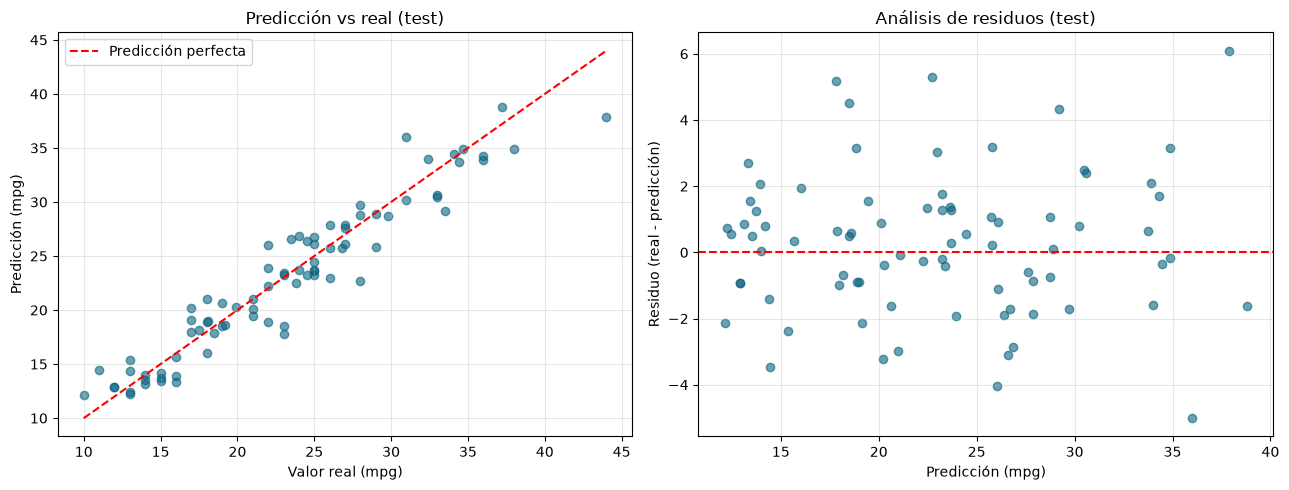

In [47]:
# Comparativa visual: predicción vs valor real (en test)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1) Predicción vs real
axes[0].scatter(y_true_test, y_pred_test, alpha=0.6, color='#08627F')
lims = [min(y_true_test.min(), y_pred_test.min()), max(y_true_test.max(), y_pred_test.max())]
axes[0].plot(lims, lims, 'r--', label='Predicción perfecta')
axes[0].set_xlabel('Valor real (mpg)'); axes[0].set_ylabel('Predicción (mpg)')
axes[0].set_title('Predicción vs real (test)'); axes[0].legend(); axes[0].grid(alpha=0.3)

# 2) Residuos
residuos = y_true_test - y_pred_test
axes[1].scatter(y_pred_test, residuos, alpha=0.6, color='#08627F')
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel('Predicción (mpg)'); axes[1].set_ylabel('Residuo (real - predicción)')
axes[1].set_title('Análisis de residuos (test)'); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

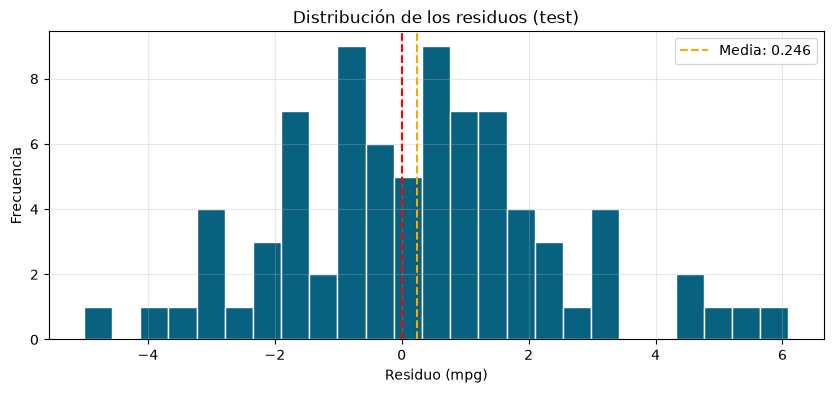

In [48]:
# Distribución de los residuos: ¿están centrados en 0? ¿son simétricos?
plt.figure(figsize=(10, 4))
plt.hist(residuos, bins=25, color='#08627F', edgecolor='white')
plt.axvline(0, color='red', linestyle='--')
plt.axvline(residuos.mean(), color='orange', linestyle='--', label=f'Media: {residuos.mean():.3f}')
plt.title('Distribución de los residuos (test)')
plt.xlabel('Residuo (mpg)'); plt.ylabel('Frecuencia')
plt.legend(); plt.grid(alpha=0.3); plt.show()

---

## 4.2 - Obtención de la importancia de las características utilizadas en el modelo entrenado

In [49]:
# Importancia por ganancia: cuánto contribuye cada feature a reducir la loss
feat_importance = xgb_model.get_score(importance_type='gain')
# Mapeamos las claves 'f0', 'f1'... a los nombres reales si es necesario
if all(k.startswith('f') and k[1:].isdigit() for k in feat_importance.keys()):
    feat_importance = {features[int(k[1:])]: v for k, v in feat_importance.items()}

# Ordenamos
imp_sorted = dict(sorted(feat_importance.items(), key=lambda x: x[1], reverse=True))
print('Importancia de características (gain):')
for k, v in imp_sorted.items():
    print(f'  {k:25s} {v:.3f}')

Importancia de características (gain):
  cylinders                 482.818
  weight                    201.578
  displacement              198.155
  horsepower                162.553
  model_year                99.656
  years_since_oldest        72.713
  origin_USA                54.037
  origin_Europa             24.741
  weight_per_hp             20.099
  acceleration              19.335
  origin_Japon              18.635


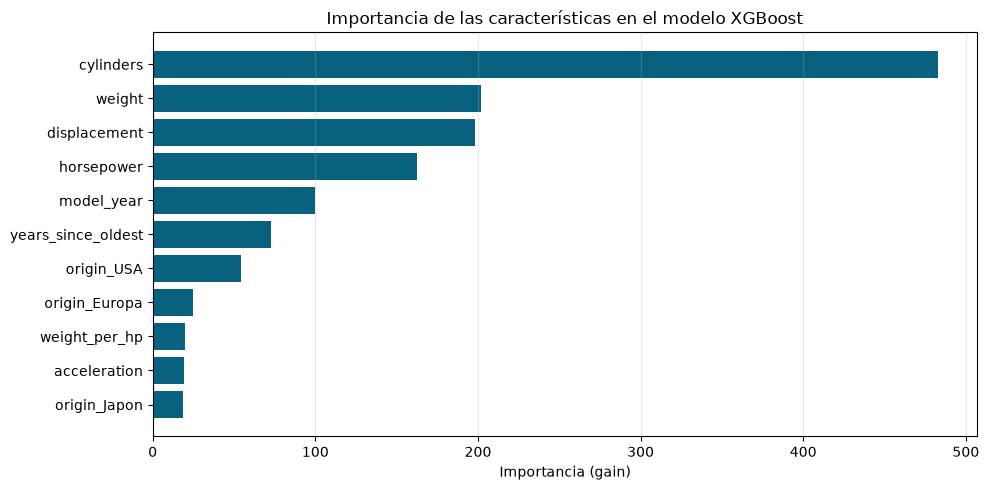

In [50]:
# Visualización
plt.figure(figsize=(10, 5))
plt.barh(list(imp_sorted.keys())[::-1], list(imp_sorted.values())[::-1], color='#08627F')
plt.xlabel('Importancia (gain)')
plt.title('Importancia de las características en el modelo XGBoost')
plt.grid(alpha=0.3, axis='x')
plt.tight_layout(); plt.show()

---

# 5 - Conclusión

Hemos construido un modelo de **regresión supervisada** que predice el consumo de combustible de un coche (mpg) a partir de sus características técnicas, recorriendo el flujo completo: carga del dataset, EDA, ingeniería de características, entrenamiento, búsqueda de hiperparámetros y evaluación.

Tres ideas para llevarse:

- La **regresión** es el problema dual de la clasificación: en lugar de predecir una etiqueta predecimos un valor continuo. El pipeline (carga, EDA, procesado, modelado, evaluación) es prácticamente idéntico; cambian la función objetivo del modelo (`reg:squarederror`) y las métricas (MAE, RMSE, R² en lugar de accuracy o matriz de confusión).
- El **EDA bivariado** (scatter plots de cada variable contra el target) es especialmente útil en regresión, porque deja ver de un vistazo si la relación es lineal, monótona o más compleja, y guía las decisiones de ingeniería de características.
- El **análisis de residuos** es la herramienta de diagnóstico más potente en regresión. Si los residuos están centrados en cero y son simétricos, el modelo se comporta bien; si muestran patrones (curvatura, varianza creciente, sesgo), nos está diciendo que algo le falta al modelo y dónde mirar para mejorarlo.